# Week 2: Baseline and first results

**Question:** if we use yesterday's average fee to predict today's fee, how far off are we on average?

Input: `data/processed/bitcoin_daily.csv`, produced by `01_prepare_data.ipynb`. Only the 2023 validation dates are scored; 2024 stays reserved for the final test.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Works whether the notebook is started from the repository root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "processed" / "bitcoin_daily.csv"

# Previous day's transaction count; must match the column name used in notebook 01
TX_LAG_1 = "txcnt_lag_1"

## 1. Load and check the dataset

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["target_date"]).sort_values("target_date").reset_index(drop=True)

required = ["target_date", "split", "actual_fee_sat", "fee_lag_1_sat", TX_LAG_1]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing columns: {missing}. Found: {list(df.columns)}"
assert df["target_date"].is_unique, "Duplicate target dates"
assert df[required].notna().all().all(), "Missing values in required columns"

# No leakage: fee_lag_1_sat must equal the fee observed on the previous calendar day
observed = df.set_index("target_date")["actual_fee_sat"]
previous = (df["target_date"] - pd.Timedelta(days=1)).map(observed)
checkable = previous.notna()
assert (df.loc[checkable, "fee_lag_1_sat"] - previous[checkable]).abs().max() < 1e-3, "fee_lag_1_sat is not yesterday's fee"

print(f"{len(df)} rows, {df['target_date'].min():%Y-%m-%d} to {df['target_date'].max():%Y-%m-%d}")

1820 rows, 2020-01-08 to 2024-12-31


## 2. Baseline

`prediction_sat = fee_lag_1_sat`: tomorrow's forecast is today's observed fee. Nothing is trained.

In [3]:
def baseline_predict(frame):
    return frame["fee_lag_1_sat"].rename("prediction_sat")

### Check by hand

Sunday's fee is 8,000 sat, so Monday's prediction is 8,000. Monday's actual fee is 7,500, so the absolute error is 500.

In [4]:
example = pd.DataFrame({"actual_fee_sat": [7_500], "fee_lag_1_sat": [8_000]})
prediction = baseline_predict(example)
assert prediction.iloc[0] == 8_000
assert mean_absolute_error(example["actual_fee_sat"], prediction) == 500
print("Hand check passed: prediction 8,000 sat, absolute error 500 sat")

Hand check passed: prediction 8,000 sat, absolute error 500 sat


## 3. Validation score (2023)

In [5]:
val = df[df["split"] == "validation"].copy()
assert (val["target_date"].dt.year == 2023).all(), "Validation must contain only 2023"
assert len(val) == 365, f"Expected 365 validation days, got {len(val)}"

val["prediction_sat"] = baseline_predict(val)
val["abs_error_sat"] = (val["actual_fee_sat"] - val["prediction_sat"]).abs()
mae = mean_absolute_error(val["actual_fee_sat"], val["prediction_sat"])

print(f"Days evaluated        : {len(val)}")
print(f"MAE                   : {mae:,.0f} sat/transaction")
print(f"Median absolute error : {val['abs_error_sat'].median():,.0f} sat/transaction")
print(f"Ten worst days        : {val['abs_error_sat'].nlargest(10).sum() / val['abs_error_sat'].sum():.0%} of the total error")
print(f"Mean observed fee     : {val['actual_fee_sat'].mean():,.0f} sat/transaction")

Days evaluated        : 365
MAE                   : 3,125 sat/transaction
Median absolute error : 1,257 sat/transaction
Ten worst days        : 25% of the total error
Mean observed fee     : 13,289 sat/transaction


## 4. Predicted and observed fees

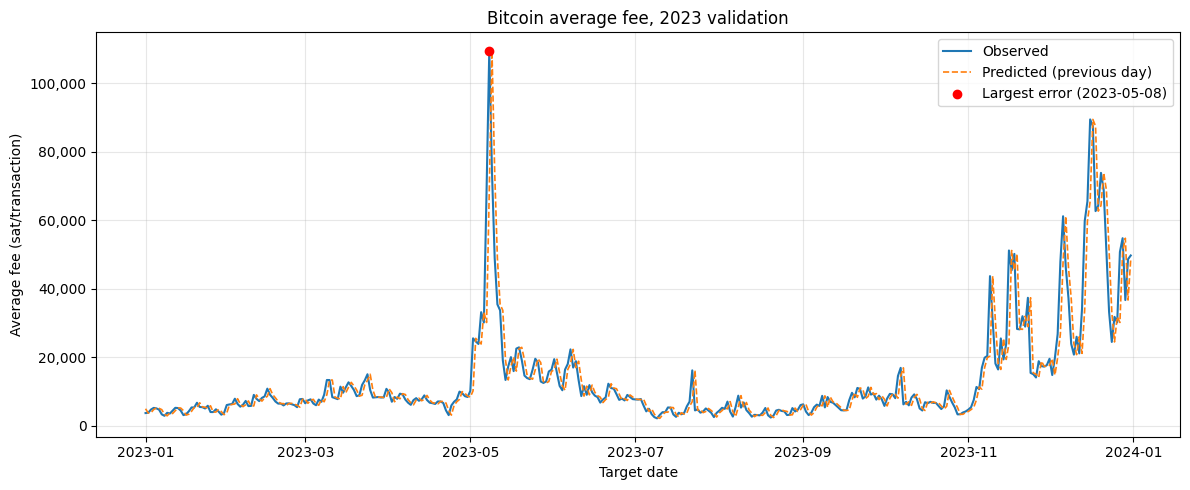

In [6]:
worst = val.loc[val["abs_error_sat"].idxmax()]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(val["target_date"], val["actual_fee_sat"], label="Observed", linewidth=1.5)
ax.plot(val["target_date"], val["prediction_sat"], label="Predicted (previous day)", linewidth=1.2, linestyle="--")
ax.scatter([worst["target_date"]], [worst["actual_fee_sat"]], color="red", zorder=3,
           label=f"Largest error ({worst['target_date']:%Y-%m-%d})")
ax.set(title="Bitcoin average fee, 2023 validation", xlabel="Target date", ylabel="Average fee (sat/transaction)")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Largest error

In [7]:
def tx_count(day):
    """Transaction count on `day`, read from the next day's lag column."""
    return df.set_index("target_date").loc[day + pd.Timedelta(days=1), TX_LAG_1]

day = worst["target_date"]
detail = pd.DataFrame({
    "fee_sat": [worst["prediction_sat"], worst["actual_fee_sat"]],
    "tx_count": [tx_count(day - pd.Timedelta(days=1)), tx_count(day)],
}, index=[f"{day - pd.Timedelta(days=1):%Y-%m-%d} (= prediction)", f"{day:%Y-%m-%d} (actual)"])
detail["total_fees_btc"] = detail["fee_sat"] * detail["tx_count"] / 1e8

print(f"Absolute error on {day:%Y-%m-%d}: {worst['abs_error_sat']:,.0f} sat/transaction")
display(detail.round(1))
display((detail.pct_change().iloc[[1]] * 100).round(1).rename(index=lambda _: "change (%)"))

Absolute error on 2023-05-08: 40,801 sat/transaction


,fee_sat,tx_count,total_fees_btc
2023-05-07 (= prediction),68676.5,614264,421.9
2023-05-08 (actual),109477.2,573864,628.3


,fee_sat,tx_count,total_fees_btc
change (%),59.4,-6.6,48.9


## 6. Interpretation

- **Score to beat in Week 3: MAE of 3,125 sat/transaction over 365 days.** The median error is much lower (1,257 sat): most days are predicted fairly well and a few spikes raise the average. The ten worst days account for about 25% of the total error.
- **Largest error: 8 May 2023.** The baseline predicted 68,676 sat and the observed fee was 109,477 sat, an error of 40,801 sat. Compared with 7 May, total fees rose from 422 to 628 BTC (+49%) while transactions fell from 614,264 to 573,864 (-7%). The average fee therefore jumped because users paid much more per transaction, not because more transactions were confirmed.
- **Possible cause (outside this dataset):** this period coincides with the congestion attributed to BRC-20 token minting. Our data alone cannot confirm that.
- **Limitation:** the baseline is always one day late. It misses the start of a spike, then misses again when fees fall back.